# Lab 07 — Failure Atlas

## The story

In Week 5 your trained model beat every simple feed. One number, NDCG@10 on the test set, said so. That number is an **average over about 1 800 moments**: 1 800 times a real person opened the app and liked something. An average can be high while a whole group of those people is served badly, and the average will never tell you.

This week you do not train anything. This notebook takes the model you already have and **maps where it fails**: for which users, for which kind of movie, by how much, and whether the failure is real or just noise. The result is a **Failure Atlas**: one figure with four panels, and a check that what we found on the validation set still holds on the test set.

## How this notebook works

**You do not write any code.** Upload your two files, then run every cell from top to bottom (in Colab: *Runtime → Run all*). Each step explains what it computes and ends with **Look at**: what to notice in its output. The last cell prints your `RESULTS` block.

| Step | What it does |
|---|---|
| 0 | loads your two files and checks the Week 6 fingerprint |
| 1 | scores the four strategies on the same moments |
| 2 | the score of every strategy per group |
| 3 | **how sure are we?** the bootstrap interval, and why it must be *paired* |
| 4 | the trained model against the best simple feed, group by group |
| 5 | the Failure Atlas: four panels, checked by a chart linter |
| 6 | the same groups on the test set: does each finding hold? |

## Inputs (two files you already have)

| File | From | Lost it? |
|---|---|---|
| `feature_table.parquet` | the Week 6 Colab (`week06.ipynb`) | re-run `week06.ipynb`: same file, same fingerprint |
| `like_model.npz` | your Week 5 lab (also in your InstaKill repository, for example `models/like_model.npz`) | re-run `week05.ipynb` with your solution |

Only `numpy`, `pandas` and `matplotlib`: every chart and every interval is built in plain code you can read.

## Words used below

- **moment**: one real like, hidden among 99 random movies. The strategy must rank the liked movie high. The **validation set** has 1 808 moments, the **test set** 1 753.
- **trained model**: your Week 5 network (`learned` in the code). **Simple feeds**: `chronological`, `popularity`, `for_you`.
- **group**: a subset of moments, for example "new users" or "movies less than a year old". The code calls it a *slice*.

In [1]:
%pip -q install numpy pandas pyarrow matplotlib

In [2]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
K = 10                                          # the feed shows 10 items: NDCG@10
CANDIDATES = 100                                # one moment = 1 liked movie + 99 random movies
FEATURES = ["freshness", "affinity", "popularity", "activity", "lifetime", "age"]
SYSTEMS = ["chronological", "popularity", "for_you", "learned"]
BASELINES = ["chronological", "popularity", "for_you"]
GROUP_COLUMNS = ["user_group", "item_age_group"]
GROUP_ORDER = {"user_group": ["new (<10 likes)", "casual (10-49)", "regular (50-199)", "power (200+)"],
               "item_age_group": ["<1 year", "1-5 years", "5-15 years", "15+ years"]}
MIN_SLICE = 50                                  # a group with fewer moments is too small to say anything about

FEATURE_FILE, MODEL_FILE = Path("feature_table.parquet"), Path("like_model.npz")
EXPECTED_HASH = "977334c6261823d4847242cd1220e21595411fb5934b2d50931d60dcdc1de87b"   # the Week 6 reference fingerprint
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0


## Step 0 — Load your two files

In Colab, the next cell asks you to upload what is missing (you can select both files at once). Locally, put them next to this notebook.

The cell then recomputes the **fingerprint** of the feature table exactly as Week 6 did. A match means you have byte-for-byte the table everybody else has. A different fingerprint usually means different library versions; the cell says so, and the notebook still runs.

In [4]:
missing = [p.name for p in (FEATURE_FILE, MODEL_FILE) if not p.exists()]
if missing:
    try:
        from google.colab import files
        print("Upload:", ", ".join(missing))
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {', '.join(missing)} next to this notebook (see the table above).")
for p in (FEATURE_FILE, MODEL_FILE):
    assert p.exists(), f"{p.name} is still missing: upload it (the file name must be exactly {p.name})"

TABLE = pd.read_parquet(FEATURE_FILE)
fingerprint = hashlib.sha256(TABLE.to_csv(index=False, float_format="%.6f", lineterminator="\n").encode("utf-8")).hexdigest()
FINGERPRINT_OK = fingerprint == EXPECTED_HASH
print(f"{FEATURE_FILE}: {len(TABLE):,} rows x {TABLE.shape[1]} columns")
print("fingerprint:", fingerprint[:16], "...", "MATCH" if FINGERPRINT_OK else
      "DIFFERENT from the reference (most likely other library versions). The notebook still runs.")

MODEL = dict(np.load(MODEL_FILE))
assert list(MODEL["features"]) == FEATURES, f"the model expects the signals {list(MODEL['features'])}"
n_params = sum(MODEL[k].size for k in ("W1", "b1", "W2", "b2"))
print(f"{MODEL_FILE}: hidden layer of {MODEL['W1'].shape[1]} neurons, {n_params} trained numbers")
assert len(TABLE) % CANDIDATES == 0 and (TABLE["label"].to_numpy().reshape(-1, CANDIDATES)[:, 0] == 1).all(), \
    "each moment must be 100 rows, the liked movie first: is this the Week 6 table?"

Upload: like_model.npz


Saving like_model.npz to like_model.npz
feature_table.parquet: 356,100 rows x 19 columns
fingerprint: 977334c6261823d4 ... MATCH
like_model.npz: hidden layer of 16 neurons, 129 trained numbers


## Step 1 — Four strategies, the same moments

The same four feed strategies that InstaKill serves, written as scorers over the six signals of the feature table:

| Strategy | Score of a candidate | In InstaKill |
|---|---|---|
| `chronological` | its freshness (newest first) | `strategy=chronological` |
| `popularity` | its popularity signal (likes of the last year; the same order for everybody) | the simplest non-personal feed |
| `for_you` | `w_fresh * freshness + w_aff * affinity + w_pop * popularity`, with the Week 4 weights | `strategy=for_you` |
| `learned` | `predict(model, signals)`: **your trained model** | `strategy=learned` |

For every moment each strategy scores the 100 candidates. The rank of the liked movie gives NDCG@10, exactly as in Week 5. The result is one table, `MOMENTS`, with **one row per moment**, one NDCG column per strategy, and the columns we group by.

The Week 4 weights default to 1, 1, 1. *Optional:* if you remember yours, change the numbers in the first line and run the cell again.

In [6]:
WEEK4_WEIGHTS = {"freshness": 1.0, "affinity": 0.2, "popularity": 2.0}     # optional: your Week 4 weights


def predict(saved, features):
    """Week 5: raw signals (n, 6) -> P(like) for each row."""
    x = (features - saved["mu"]) / saved["sd"]
    hidden = np.tanh(x @ saved["W1"] + saved["b1"])
    return 1.0 / (1.0 + np.exp(-np.clip((hidden @ saved["W2"] + saved["b2"])[:, 0], -60, 60)))


def system_scores(table):
    """One score per row of `table` for each strategy (higher = better)."""
    x = table[FEATURES].to_numpy()
    w = WEEK4_WEIGHTS
    return {"chronological": x[:, 0],
            "popularity": x[:, 2],
            "for_you": w["freshness"] * x[:, 0] + w["affinity"] * x[:, 1] + w["popularity"] * x[:, 2],
            "learned": predict(MODEL, x)}


def ndcg_per_moment(scores):
    """scores: one per row, 100 rows per moment, liked movie first. Ties count against the strategy (as in Week 5)."""
    s = np.asarray(scores, dtype=float).reshape(-1, CANDIDATES)
    rank = (s[:, 1:] >= s[:, :1]).sum(axis=1)                   # how many random movies scored at least as high
    return np.where(rank < K, 1.0 / np.log2(rank + 2), 0.0)


SCORES = system_scores(TABLE)
MOMENTS = (TABLE[TABLE["label"] == 1]
           .set_index("moment_id")[["split", "user_id", "item_id", "user_prior_likes", "item_age_days", "main_genre"] + GROUP_COLUMNS]
           .copy())
for name in SYSTEMS:
    MOMENTS[name] = ndcg_per_moment(SCORES[name])
VAL, TEST = MOMENTS[MOMENTS["split"] == "val"], MOMENTS[MOMENTS["split"] == "test"]

assert len(VAL) == 1808 and len(TEST) == 1753, "expected 1 808 validation and 1 753 test moments (the Week 5/6 split)"
print(f"{'strategy':15s} NDCG@10 on the validation set   (random guessing ~0.045)")
for name in SYSTEMS:
    print(f"{name:15s} {VAL[name].mean():.4f}   {'█' * round(80 * VAL[name].mean())}")

strategy        NDCG@10 on the validation set   (random guessing ~0.045)
chronological   0.0630   █████
popularity      0.3782   ██████████████████████████████
for_you         0.2288   ██████████████████
learned         0.4545   ████████████████████████████████████


**Look at:** the trained model (`learned`) should be first. If it is not, that is a finding about your model, not an error: the rest of the notebook maps it all the same.

## Step 2 — One average, many groups

Each moment belongs to a group of its **user** and a group of the **movie the user liked**:

| Column | Question it lets you ask | Values |
|---|---|---|
| `user_group` | does it serve people we know little about? | `new (<10 likes)`, `casual (10-49)`, `regular (50-199)`, `power (200+)` |
| `item_age_group` | does it find the liked movie when that movie is new? old? | `<1 year`, `1-5 years`, `5-15 years`, `15+ years` |

The table below is the mean NDCG@10 of every strategy per group, with the number of moments `n`.

In [7]:
def group_report(moments, by):
    """Mean NDCG@10 per strategy for each group of the column `by`, with the number of moments n."""
    report = moments.groupby(by)[SYSTEMS].mean()
    report.insert(0, "n", moments.groupby(by).size())
    return report.reindex([g for g in GROUP_ORDER[by] if g in report.index]).round(3)


display(group_report(VAL, "user_group"))
display(group_report(VAL, "item_age_group"))

,n,chronological,popularity,for_you,learned
user_group,,,,,
new (<10 likes),191,0.061,0.534,0.395,0.618
casual (10-49),619,0.056,0.468,0.281,0.538
regular (50-199),715,0.053,0.337,0.167,0.421
power (200+),283,0.106,0.181,0.160,0.246


,n,chronological,popularity,for_you,learned
item_age_group,,,,,
<1 year,104,0.617,0.376,0.753,0.267
1-5 years,281,0.175,0.343,0.380,0.283
5-15 years,844,0.001,0.372,0.165,0.423
15+ years,579,0.000,0.405,0.154,0.617


**Look at:**

- the **level** changes a lot between groups (every strategy is worse for power users);
- the **order** of the strategies changes too: compare the `<1 year` row with the `15+ years` row. The order is what decides which strategy InstaKill should serve to whom.

What the table does **not** tell you is whether a difference of 0.03 in a group of 104 moments means anything. That is Step 3.

## Step 3 — How sure are we? The bootstrap

For the same moments we have the NDCG of strategy A and of strategy B. Their mean difference is one number. With a *different* 1 808 moments from the same kind of users and movies, we would get a slightly different number. The **bootstrap** estimates how different, using only the data we have:

1. compute the difference per moment, `d = a - b`;
2. draw `len(d)` moments **with replacement** (some appear twice, some not at all) and take the mean of their `d`;
3. repeat 2 000 times: we now have 2 000 plausible means;
4. the **95 % interval** is the range of the middle 95 % of those means (the 2.5th and 97.5th percentile).

If the interval is entirely above 0, A wins; entirely below 0, A loses; if it contains 0, we **cannot tell**.

It must be **paired**: the same resampled moment is used for A and for B. Two strategies are both bad on hard moments and both good on easy ones; resampling each of them on its own throws that away and gives an interval that is too wide.

In [8]:
def paired_bootstrap(a, b, n_boot=2000, seed=SEED):
    """95% bootstrap interval of mean(a - b), resampling moments (the same moment for a and b)."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, len(d), size=(n_boot, len(d)))].mean(axis=1)    # one row of indices per resample
    low, high = np.percentile(means, [2.5, 97.5])
    return {"diff": float(d.mean()), "low": float(low), "high": float(high)}


def unpaired_bootstrap(a, b, n_boot=2000, seed=SEED):
    """The WRONG way, for comparison: resample a and b separately, as if they were different moments."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    means = (a[rng.integers(0, len(a), size=(n_boot, len(a)))].mean(axis=1)
             - b[rng.integers(0, len(b), size=(n_boot, len(b)))].mean(axis=1))
    low, high = np.percentile(means, [2.5, 97.5])
    return {"diff": float((a - b).mean()), "low": float(low), "high": float(high)}


def verdict(r):
    return "wins" if r["low"] > 0 else "loses" if r["high"] < 0 else "unclear"


new_users = VAL[VAL["user_group"] == "new (<10 likes)"]
best = new_users[BASELINES].mean().idxmax()
print(f"trained model minus {best} (the best simple feed for new users), {len(new_users)} moments:\n")
for name, fn, part in [("paired,   all moments", paired_bootstrap, VAL), ("paired,   new users", paired_bootstrap, new_users),
                       ("UNPAIRED, new users", unpaired_bootstrap, new_users)]:
    r = fn(part["learned"], part[best])
    print(f"{name:22s} {r['diff']:+.3f}   95% interval {r['low']:+.3f} .. {r['high']:+.3f}   width {r['high'] - r['low']:.3f}   -> {verdict(r)}")

trained model minus popularity (the best simple feed for new users), 191 moments:

paired,   all moments  +0.076   95% interval +0.065 .. +0.087   width 0.022   -> wins
paired,   new users    +0.084   95% interval +0.050 .. +0.121   width 0.070   -> wins
UNPAIRED, new users    +0.084   95% interval +0.003 .. +0.165   width 0.162   -> wins


**Look at:**

- fewer moments give a **wider** interval: all moments vs new users only;
- the same data with the **unpaired** (wrong) method gives a much wider interval, sometimes wide enough to turn a clear result into "unclear". The method changed the conclusion, not the data.

## Step 4 — Against the best simple feed, group by group

For each group, the trained model is compared with **the best of the three simple feeds in that group** (the one with the highest mean NDCG there; it can be a different one in each group). That is the honest comparison: if InstaKill can serve a different strategy to new posts, the trained model must beat whichever is best there, not the weakest.

One row per group, worst group for the trained model first:

| Column | Meaning |
|---|---|
| `n` | number of moments in the group |
| `learned`, `baseline_ndcg` | mean NDCG@10 of the trained model and of the best simple feed (`best_baseline`) |
| `diff`, `low`, `high` | the paired bootstrap: difference and its 95 % interval |
| `verdict` | `wins` (interval above 0), `loses` (below 0), `unclear` (contains 0) |

In [9]:
def lift_table(moments, by, min_n=MIN_SLICE):
    """The trained model vs the best simple feed in each group of `by`, with a paired bootstrap interval and a verdict."""
    rows = {}
    for value, part in moments.groupby(by):
        if len(part) < min_n:
            continue
        best = part[BASELINES].mean().idxmax()
        r = paired_bootstrap(part["learned"], part[best])
        rows[value] = {"n": len(part), "learned": part["learned"].mean(), "best_baseline": best,
                       "baseline_ndcg": part[best].mean(), **r, "verdict": verdict(r)}
    return pd.DataFrame.from_dict(rows, orient="index").sort_values("diff")


LIFT_VAL = pd.concat({by: lift_table(VAL, by) for by in GROUP_COLUMNS}, names=["column", "group"])
LIFT_VAL.round(3)

n  learned best_baseline  baseline_ndcg  \
column         group                                                         
user_group     power (200+)      283    0.246    popularity          0.181   
               casual (10-49)    619    0.538    popularity          0.468   
               new (<10 likes)   191    0.618    popularity          0.534   
               regular (50-199)  715    0.421    popularity          0.337   
item_age_group <1 year           104    0.267       for_you          0.753   
               1-5 years         281    0.283       for_you          0.380   
               5-15 years        844    0.423    popularity          0.372   
               15+ years         579    0.617    popularity          0.405   

                                  diff    low   high verdict  
column         group                                          
user_group     power (200+)      0.065  0.040  0.090    wins  
               casual (10-49)    0.070  0.052  0.089    wins  
               new (<10 likes)   0.084  0.050  0.121    wins  
               regular (50-199)  0.084  0.065  0.102    wins  
item_age_group <1 year          -0.487 -0.535 -0.438   loses  
               1-5 years        -0.097 -0.127 -0.068   loses  
               5-15 years        0.051  0.037  0.065    wins  
               15+ years         0.212  0.193  0.231    wins

**Look at:** the `verdict` column. Find the groups where the trained model **loses** or is **unclear**, and which simple feed beats it there. Then ask *why*, in the language of the six signals: a movie less than a year old has freshness near 1 and almost no lifetime likes. What did your model learn about lifetime likes?

## Step 5 — The Failure Atlas

One figure, four panels, **one question per panel**. The title of each panel *is* its question.

| Panel | Question |
|---|---|
| **A** | Who wins on average, and how sure are we? (each strategy with its 95 % interval) |
| **B** | Where does the trained model lose against the best simple feed? (Step 4, every group, a line at 0) |
| **C** | How does quality change with how much we know about the user? (NDCG against the user's earlier likes) |
| **D** | When the model says P(like) = 0.8, how often is it a like? (is its probability honest?) |

Before drawing, a **chart linter** checks the rules of a clear chart that a program can check: a question as title, labelled axes, intervals on every comparison, a line at 0 for differences, bars that start at 0, a legend when there is more than one line, a colour scale centred on 0 for signed values. First, see what it says about a deliberately bad chart.

In [10]:
from matplotlib.container import ErrorbarContainer
from matplotlib.collections import LineCollection, PolyCollection, QuadMesh

COLORS = {"chronological": "#9AA6BD", "popularity": "#F7A30F", "for_you": "#10ADB6", "learned": "#0B2F63"}   # the same colours everywhere


def chart_lint(fig):
    """The checkable rules of a clear chart. Returns a list of problems (empty = all good)."""
    problems = []
    axes = [ax for ax in fig.axes if ax.get_label() != "<colorbar>"]
    if len(axes) < 4:
        return [f"the figure needs 4 panels, it has {len(axes)}"]
    width, height = fig.get_size_inches()
    if width < 10 or height < 7:
        problems.append(f"figure is {width:.0f}x{height:.0f} inches: too small to read (use at least 10x7)")
    for letter, ax in zip("ABCD", axes):
        title = ax.get_title()
        if not title.startswith(letter):
            problems.append(f"panel {letter}: the title must start with '{letter}' and ask the panel's question (got {title!r})")
        elif len(title.split()) < 5:
            problems.append(f"panel {letter}: the title should be a question, not a label (got {title!r})")
        if not ax.get_xlabel() and not ax.get_ylabel():
            problems.append(f"panel {letter}: label the axes")
        labelled = [h for h in ax.get_legend_handles_labels()[1] if not h.startswith("_")]
        if len(labelled) > 1 and ax.get_legend() is None:
            problems.append(f"panel {letter}: {len(labelled)} labelled series but no legend")
        bars = [p for p in ax.patches if type(p).__name__ == "Rectangle"]
        if bars:
            horizontal = len({round(p.get_x(), 9) for p in bars}) == 1 and len({round(p.get_y(), 9) for p in bars}) > 1
            low = ax.get_xlim()[0] if horizontal else ax.get_ylim()[0]
            if low > 1e-9 and min(p.get_width() if horizontal else p.get_height() for p in bars) >= 0:
                problems.append(f"panel {letter}: bars must start at 0 (the axis starts at {low:.3f}); use points if you want to zoom")
        for artist in [*ax.images, *[c for c in ax.collections if isinstance(c, QuadMesh)]]:
            vmin, vmax = artist.norm.vmin, artist.norm.vmax
            if vmin is not None and vmax is not None and vmin < 0 < vmax and abs(vmin + vmax) > 1e-9 * max(1, abs(vmax)):
                problems.append(f"panel {letter}: a signed colour scale must be centred on 0 (vmin={vmin:.3f}, vmax={vmax:.3f})")
    has_interval = lambda ax: (any(isinstance(c, ErrorbarContainer) for c in ax.containers)
                               or any(isinstance(c, (LineCollection, PolyCollection)) for c in ax.collections))
    for letter, ax in zip("AB", axes):
        if not has_interval(ax):
            problems.append(f"panel {letter}: show the 95% intervals (errorbar or a shaded band)")
    zero_line = any(np.allclose(line.get_xdata(), 0) or np.allclose(line.get_ydata(), 0)
                    for line in axes[1].get_lines() if len(line.get_xdata()))
    if not zero_line:
        problems.append("panel B: draw a reference line at 0 (ax.axvline(0) or ax.axhline(0))")
    if len([l for l in axes[2].get_lines() if not l.get_label().startswith("_")]) < 4:
        problems.append("panel C: one labelled line per strategy (4)")
    return problems


# a deliberately bad figure: small, bars with a cut axis, no titles, no labels, no intervals
bad, bad_axes = plt.subplots(2, 2, figsize=(6, 4))
bad_axes[0, 0].bar(SYSTEMS, VAL[SYSTEMS].mean()); bad_axes[0, 0].set_ylim(0.04, 0.5)
plt.close(bad)
print("The linter on a bad figure:\n- " + "\n- ".join(chart_lint(bad)))

The linter on a bad figure:
- figure is 6x4 inches: too small to read (use at least 10x7)
- panel A: the title must start with 'A' and ask the panel's question (got '')
- panel A: label the axes
- panel A: bars must start at 0 (the axis starts at 0.040); use points if you want to zoom
- panel B: the title must start with 'B' and ask the panel's question (got '')
- panel B: label the axes
- panel C: the title must start with 'C' and ask the panel's question (got '')
- panel C: label the axes
- panel D: the title must start with 'D' and ask the panel's question (got '')
- panel D: label the axes
- panel A: show the 95% intervals (errorbar or a shaded band)
- panel B: show the 95% intervals (errorbar or a shaded band)
- panel B: draw a reference line at 0 (ax.axvline(0) or ax.axhline(0))
- panel C: one labelled line per strategy (4)


Now the atlas itself. Read the code of each panel: every mark on the figure is one line of matplotlib, and every command goes to one `ax` (`ax_a` … `ax_d`).

The chart linter found no problems. Saved failure_atlas.png (submit it with the notebook).


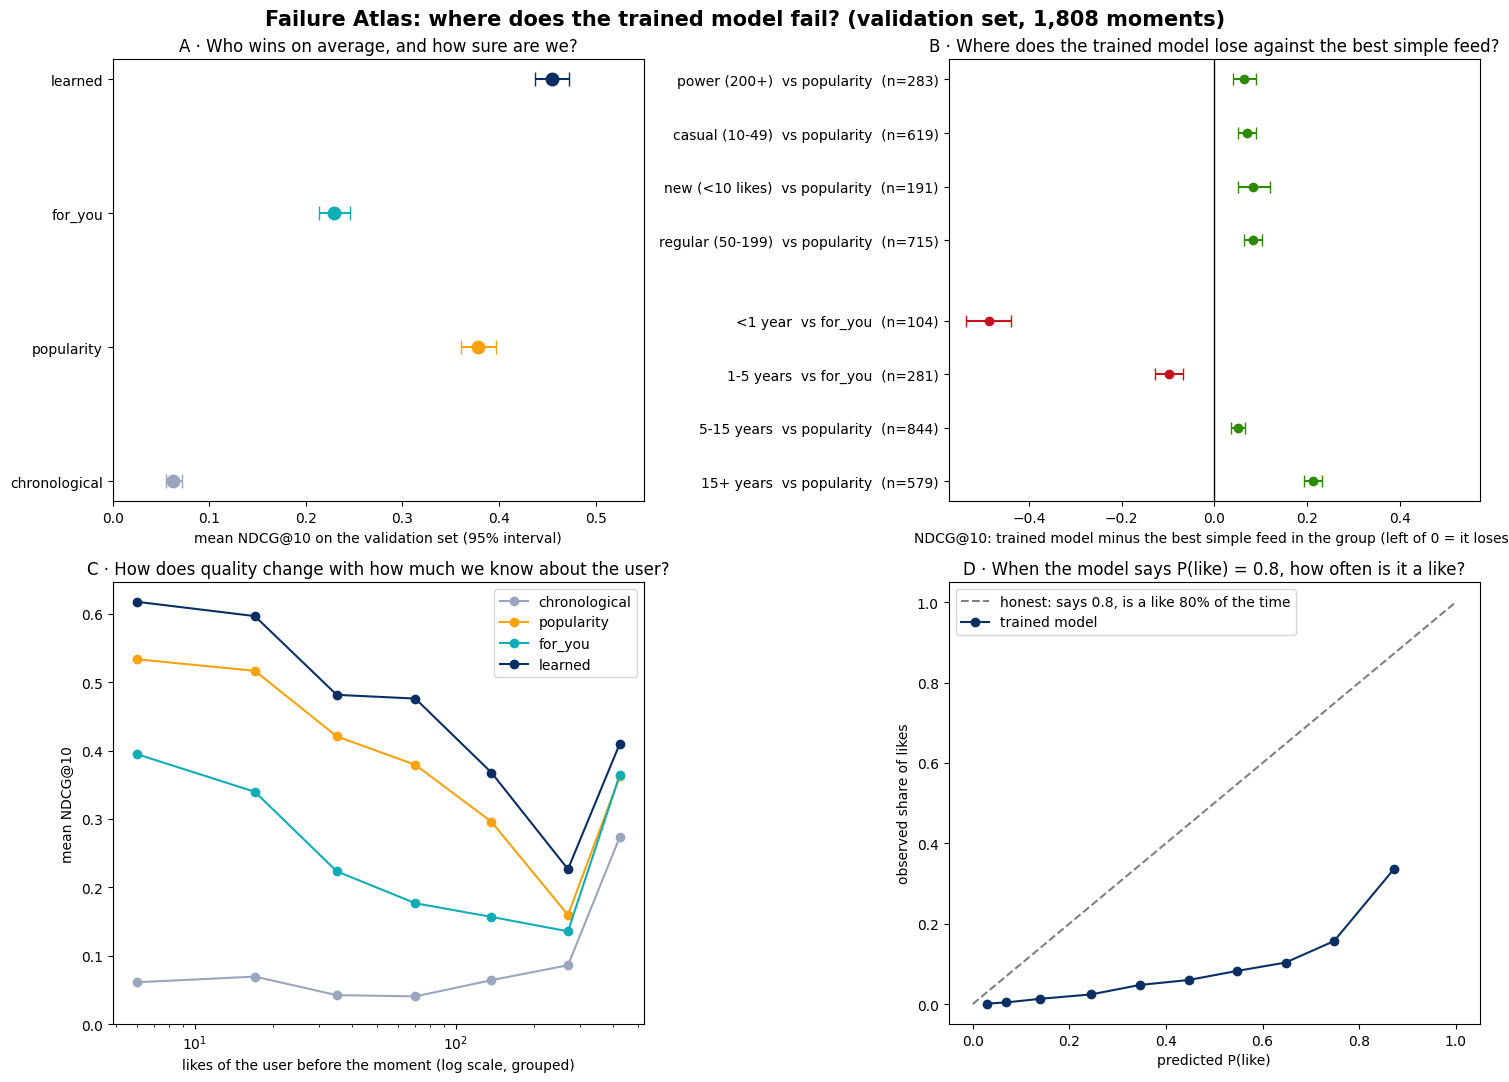

In [11]:
def draw_atlas(moments, split_name="validation set"):
    """The Failure Atlas of `moments`. Returns the matplotlib Figure."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))
    ax_a, ax_b, ax_c, ax_d = axes.ravel()

    # A: each strategy's mean with its 95% interval (the interval of one mean = paired_bootstrap against zeros)
    for i, name in enumerate(SYSTEMS):
        r = paired_bootstrap(moments[name], np.zeros(len(moments)))
        ax_a.errorbar(r["diff"], i, xerr=[[r["diff"] - r["low"]], [r["high"] - r["diff"]]], fmt="o", color=COLORS[name], capsize=5, ms=9)
    ax_a.set_yticks(range(len(SYSTEMS)), SYSTEMS)
    ax_a.set_xlim(0, 0.55)
    ax_a.set_xlabel(f"mean NDCG@10 on the {split_name} (95% interval)")
    ax_a.set_title("A · Who wins on average, and how sure are we?")

    # B: the lift table of every group, red = loses, amber = unclear, green = wins, a line at 0
    labels, positions, y = [], [], 0
    for by in GROUP_COLUMNS:
        for value, row in lift_table(moments, by).iterrows():
            color = {"wins": "#2e8a00", "loses": "#c4121e", "unclear": "#b26b00"}[row["verdict"]]
            ax_b.errorbar(row["diff"], y, xerr=[[row["diff"] - row["low"]], [row["high"] - row["diff"]]], fmt="o", color=color, capsize=4)
            labels.append(f"{value}  vs {row['best_baseline']}  (n={row['n']})")
            positions.append(y)
            y += 1
        y += 0.5                                                          # a gap between user groups and movie-age groups
    ax_b.set_yticks(positions, labels)
    ax_b.invert_yaxis()                                                   # read from the top: user groups, then movie ages
    m = max(0.5, ax_b.get_xlim()[1], -ax_b.get_xlim()[0])
    ax_b.set_xlim(-m, m)                                                  # 0 in the middle
    ax_b.axvline(0, color="black", lw=1)
    ax_b.set_xlabel("NDCG@10: trained model minus the best simple feed in the group (left of 0 = it loses)")
    ax_b.set_title("B · Where does the trained model lose against the best simple feed?")

    # C: quality against how much we know about the user (earlier likes, log-spaced bins)
    bins = [3, 10, 25, 50, 100, 200, 400, 1300]
    groups = pd.cut(moments["user_prior_likes"], bins, right=False)
    centres = moments.groupby(groups, observed=True)["user_prior_likes"].median()
    for name in SYSTEMS:
        ax_c.plot(centres, moments.groupby(groups, observed=True)[name].mean(), "o-", color=COLORS[name], label=name)
    ax_c.set_xscale("log")
    ax_c.set_ylim(0, None)
    ax_c.legend()
    ax_c.set_xlabel("likes of the user before the moment (log scale, grouped)")
    ax_c.set_ylabel("mean NDCG@10")
    ax_c.set_title("C · How does quality change with how much we know about the user?")

    # D: reliability diagram over all 100 candidates of every moment: predicted P(like) vs the observed share of likes
    rows = TABLE["split"].to_numpy() == moments["split"].iloc[0]
    p, liked = SCORES["learned"][rows], TABLE["label"].to_numpy()[rows]
    edges = np.array([0, .05, .1, .2, .3, .4, .5, .6, .7, .8, 1.0])
    b = np.digitize(p, edges[1:-1])
    keep = [k for k in range(len(edges) - 1) if (b == k).any()]
    ax_d.plot([0, 1], [0, 1], "--", color="gray", label="honest: says 0.8, is a like 80% of the time")
    ax_d.plot([p[b == k].mean() for k in keep], [liked[b == k].mean() for k in keep], "o-", color=COLORS["learned"], label="trained model")
    ax_d.set_xlabel("predicted P(like)")
    ax_d.set_ylabel("observed share of likes")
    ax_d.legend()
    ax_d.set_title("D · When the model says P(like) = 0.8, how often is it a like?")

    fig.suptitle(f"Failure Atlas: where does the trained model fail? ({split_name}, {len(moments):,} moments)", fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig


ATLAS = draw_atlas(VAL)
problems = chart_lint(ATLAS)
assert not problems, "the chart linter found problems:\n- " + "\n- ".join(problems)
ATLAS.savefig("failure_atlas.png", dpi=120, bbox_inches="tight")
print("The chart linter found no problems. Saved failure_atlas.png (submit it with the notebook).")
plt.show()

**Look at:**

- **A:** do the intervals of the trained model and of the best simple feed overlap?
- **B:** which rows are red, left of 0? The same groups as in Step 4, now readable in five seconds.
- **C:** every strategy gets worse for users with many likes. Does the trained model keep its lead?
- **D:** the gray line is an honest model. Above 0.5 the trained model's points fall far below it: it was trained with 1 like per 4 non-likes, but the feed has 1 like per 100 candidates. Its *order* can be good while its *probability* is too high.

## Step 6 — Does it hold on the test set?

Everything above was found on the **validation set**, by looking at 8 groups. With 8 groups and 95 % intervals, one of them can look like a real difference by pure chance. The honest check is **fresh data**: the same groups, the same comparison (against the same simple feed as on validation), on the **test set**, which nothing above has looked at.

A finding that changes on the test set is **not a mistake**: it is a result. It means the validation finding was a hypothesis that did not survive.

In [12]:
print(f"{'strategy':15s} test NDCG@10   95% interval")
for name in SYSTEMS:
    r = paired_bootstrap(TEST[name], np.zeros(len(TEST)))
    print(f"{name:15s} {r['diff']:.4f}        {r['low']:.4f} .. {r['high']:.4f}")

rows = []
for (by, value), on_val in LIFT_VAL.iterrows():
    part = TEST[TEST[by] == value]
    r = paired_bootstrap(part["learned"], part[on_val["best_baseline"]])
    rows.append({"column": by, "group": value, "against": on_val["best_baseline"],
                 "val diff": round(on_val["diff"], 3), "val": on_val["verdict"],
                 "test n": len(part), "test diff": round(r["diff"], 3),
                 "test interval": f"{r['low']:+.3f} .. {r['high']:+.3f}", "test": verdict(r),
                 "holds": verdict(r) == on_val["verdict"]})
REPLICATION = pd.DataFrame(rows)
REPLICATION

strategy        test NDCG@10   95% interval
chronological   0.0427        0.0355 .. 0.0502
popularity      0.3785        0.3608 .. 0.3965
for_you         0.1735        0.1576 .. 0.1894
learned         0.4599        0.4416 .. 0.4770


,column,group,against,val diff,val,test n,test diff,test interval,test,holds
0,user_group,power (200+),popularity,0.065,wins,375,0.070,+0.047 .. +0.096,wins,True
1,user_group,casual (10-49),popularity,0.070,wins,537,0.087,+0.066 .. +0.109,wins,True
2,user_group,new (<10 likes),popularity,0.084,wins,133,0.073,+0.032 .. +0.114,wins,True
3,user_group,regular (50-199),popularity,0.084,wins,708,0.085,+0.065 .. +0.103,wins,True
4,item_age_group,<1 year,for_you,-0.487,loses,89,-0.472,-0.532 .. -0.416,loses,True
5,item_age_group,1-5 years,for_you,-0.097,loses,321,-0.017,-0.051 .. +0.018,unclear,False
6,item_age_group,5-15 years,popularity,0.051,wins,622,0.050,+0.032 .. +0.068,wins,True
7,item_age_group,15+ years,popularity,0.212,wins,721,0.187,+0.169 .. +0.204,wins,True


**Look at:** the `holds` column. A group that **loses** on both sets is a real failure of your model: that is what InstaKill must fix or route around (for example, serve `for_you` to new posts). A group that changed is a finding you should not have trusted from the validation set alone.

## RESULTS

The next cell writes your `RESULTS` block from the numbers above. Nothing to fill in: run it and leave its output in the notebook you submit.

In [13]:
worst = LIFT_VAL["diff"].idxmin()
w = LIFT_VAL.loc[worst]
lines = ["RESULTS",
         f"fingerprint: {fingerprint[:16]} {'MATCH' if FINGERPRINT_OK else 'DIFFERENT'}",
         "overall (test): " + " | ".join(
             f"{n} {r['diff']:.3f} [{r['low']:.3f}, {r['high']:.3f}]"
             for n, r in ((n, paired_bootstrap(TEST[n], np.zeros(len(TEST)))) for n in SYSTEMS)),
         f"worst group for the trained model (validation): {worst[0]} = {worst[1]}, vs {w['best_baseline']}, "
         f"{w['diff']:+.3f} [{w['low']:+.3f}, {w['high']:+.3f}], {w['verdict']}",
         "loses on validation: " + (", ".join(f"{g}" for (_, g), v in LIFT_VAL["verdict"].items() if v == "loses") or "none"),
         f"groups that hold on test: {int(REPLICATION['holds'].sum())} of {len(REPLICATION)}"
         + ("" if REPLICATION["holds"].all() else
            " (changed: " + ", ".join(f"{r.group} {r.val}->{r.test}" for r in REPLICATION[~REPLICATION["holds"]].itertuples()) + ")")]
print("\n".join(lines))

RESULTS
fingerprint: 977334c6261823d4 MATCH
overall (test): chronological 0.043 [0.036, 0.050] | popularity 0.379 [0.361, 0.397] | for_you 0.173 [0.158, 0.189] | learned 0.460 [0.442, 0.477]
worst group for the trained model (validation): item_age_group = <1 year, vs for_you, -0.487 [-0.535, -0.438], loses
loses on validation: <1 year, 1-5 years
groups that hold on test: 7 of 8 (changed: 1-5 years loses->unclear)


**Next, in InstaKill** (see the assignment overview): the same question on your own data. `scripts/evaluate.py` replays your database at a cut-off time, calls the four strategies through the service code your endpoint uses, and writes a table with intervals and a static dashboard.